# 07. Hồi quy tuyến tính dự báo doanh thu

**Issue #6** – Chuyển sang mức **Dự đoán (Predictive)** theo lộ trình khóa học (Tuần 10 – Linear Regression).

### Mục tiêu
- Xây dựng mô hình **Linear Regression** dự báo doanh thu
- Đánh giá bằng R², MAE, RMSE và biểu đồ
- Giải thích hệ số hồi quy theo góc nhìn kinh doanh

### Biến mục tiêu
- `Log_Sales = log(1 + Sales)` — giảm ảnh hưởng phân phối lệch phải


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

pd.set_option("display.max_columns", 50)
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("Set2")
print("Đã import thư viện thành công")

Đã import thư viện thành công


## 1. Đọc dữ liệu đã xử lý
Ưu tiên `data/processed/superstore_cleaned.csv`. Nếu không có, fallback sang `data/raw/train.csv`.


In [3]:
# Tìm file dữ liệu (chạy được cả từ notebooks/ lẫn thư mục gốc)
candidates = [
    "../data/processed/superstore_cleaned.csv",
    "data/processed/superstore_cleaned.csv",
    "../data/raw/train.csv",
    "data/raw/train.csv",
    "train.csv",
]

df = None
used_path = None
for path in candidates:
    if os.path.exists(path):
        df = pd.read_csv(path)
        used_path = path
        break

if df is None:
    raise FileNotFoundError(
        "Không tìm thấy file dữ liệu. Hãy đảm bảo có data/processed/superstore_cleaned.csv hoặc data/raw/train.csv"
    )

df.columns = [c.strip() for c in df.columns]
print(f"Đã đọc: {used_path}")
print(f"Kích thước: {df.shape[0]:,} dòng × {df.shape[1]} cột")
print("Các cột:", df.columns.tolist())
df.head(3)


Đã đọc: ../data/processed/superstore_cleaned.csv
Kích thước: 9,789 dòng × 31 cột
Các cột: ['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Year', 'Month', 'Quarter', 'DayOfWeek', 'Is_Weekend', 'Ship_Days', 'Cust_Order_Count', 'Cust_Item_Count', 'Cust_Mean_Sales', 'SubCat_Mean_Sales', 'Is_Outlier', 'Log_Sales', 'Sales_Capped']


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Year,Month,Quarter,DayOfWeek,Is_Weekend,Ship_Days,Cust_Order_Count,Cust_Item_Count,Cust_Mean_Sales,SubCat_Mean_Sales,Is_Outlier,Log_Sales,Sales_Capped
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2017,11,4,Wednesday,0,3,3,5,229.756,486.259105,0,5.572002,261.960
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,2017,11,4,Wednesday,0,3,3,5,229.756,531.530579,1,6.597064,500.108
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2017,6,2,Monday,0,4,5,9,124.387,34.587468,0,2.748552,14.620


# Parse ngày an toàn (hỗ trợ cả YYYY-MM-DD từ superstore_cleaned.csv và DD/MM/YYYY từ train.csv)
for col in ["Order Date", "Ship Date"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], format="mixed", dayfirst=True, errors="coerce")

# Tạo các biến thời gian & hành vi khách hàng (nếu thiếu)
if "Month" not in df.columns and "Order Date" in df.columns:
    df["Month"] = df["Order Date"].dt.month

if "Ship_Days" not in df.columns and {"Order Date", "Ship Date"}.issubset(df.columns):
    df["Ship_Days"] = (df["Ship Date"] - df["Order Date"]).dt.days

if "Is_Weekend" not in df.columns and "Order Date" in df.columns:
    df["Is_Weekend"] = df["Order Date"].dt.dayofweek.isin([5, 6]).astype(int)

if "Cust_Order_Count" not in df.columns and {"Customer ID", "Order ID"}.issubset(df.columns):
    df["Cust_Order_Count"] = df.groupby("Customer ID")["Order ID"].transform("nunique")

if "Cust_Mean_Sales" not in df.columns and "Customer ID" in df.columns:
    df["Cust_Mean_Sales"] = df.groupby("Customer ID")["Sales"].transform("mean")

# Log_Sales & Log_Cust_Mean_Sales
if "Sales" not in df.columns:
    raise KeyError("Không tìm thấy cột Sales")
df["Log_Sales"] = np.log1p(df["Sales"])
df["Log_Cust_Mean_Sales"] = np.log1p(df["Cust_Mean_Sales"])

# Loại dòng thiếu biến bắt buộc
required = ["Sales", "Category", "Sub-Category", "Region", "Segment", "Ship Mode"]
optional_num = [c for c in ["Month", "Ship_Days", "Is_Weekend", "Cust_Order_Count", "Log_Cust_Mean_Sales"] if c in df.columns]
df = df.dropna(subset=required + optional_num).copy()

# Ship_Days âm (lỗi ngày) → loại
if "Ship_Days" in df.columns:
    df = df[df["Ship_Days"] >= 0].copy()

print("Shape sau làm sạch:", df.shape)
print(df[["Sales", "Log_Sales", "Category", "Sub-Category", "Region", "Segment", "Ship Mode"] + optional_num].describe(include="all").T)

In [4]:
## 3. Chọn biến độc lập (X) và biến mục tiêu (y)

| Vai trò | Biến | Lý do |
|---------|------|--------|
| Mục tiêu | `Log_Sales` | Giảm lệch phải của `Sales` (`Skewness` từ 13.05 về 0.28) |
| Phân loại | `Sub-Category`, `Region`, `Segment`, `Ship Mode` | `Sub-Category` (17 mức) phản ánh trực tiếp chênh lệch đơn giá ngành hàng từ Diagnostic (thay cho `Category` 3 mức để tránh đa cộng tuyến phân cấp hoàn hảo); kết hợp vùng, phân khúc và phương thức giao |
| Số | `Month`, `Ship_Days`, `Is_Weekend`, `Cust_Order_Count`, `Log_Cust_Mean_Sales` | Thời vụ, vận hành và sức mua lịch sử của khách hàng |

Shape sau làm sạch: (9789, 31)
            count unique              top  freq        mean         std  \
Sales      9789.0    NaN              NaN   NaN  230.116193  625.302079   
Log_Sales  9789.0    NaN              NaN   NaN    4.156481    1.590884   
Category     9789      3  Office Supplies  5903         NaN         NaN   
Region       9789      4             West  3140         NaN         NaN   
Segment      9789      3         Consumer  5096         NaN         NaN   
Month      9789.0    NaN              NaN   NaN    7.822658    3.277864   
Ship_Days  9789.0    NaN              NaN   NaN    3.961181    1.750452   

                min       25%       50%       75%        max  
Sales         0.444    17.248    54.384   210.392   22638.48  
Log_Sales  0.367417  2.904055  4.014291  5.353714  10.027451  
Category        NaN       NaN       NaN       NaN        NaN  
Region          NaN       NaN       NaN       NaN        NaN  
Segment         NaN       NaN       NaN       NaN    

cat_cols = ["Sub-Category", "Region", "Segment", "Ship Mode"]
num_cols = [c for c in ["Month", "Ship_Days", "Is_Weekend", "Cust_Order_Count", "Log_Cust_Mean_Sales"] if c in df.columns]

# Kiểm tra cột tồn tại
for c in cat_cols:
    if c not in df.columns:
        raise KeyError(f"Thiếu cột phân loại: {c}")

X = df[cat_cols + num_cols].copy()
y = df["Log_Sales"].copy()

print("Biến phân loại:", cat_cols)
print("Biến số:", num_cols)
print("X:", X.shape, "| y:", y.shape)
print("\nMissing trong X:")
print(X.isna().sum())
print("\nPhân phối các biến phân loại:")
for c in cat_cols:
    print(f"  {c}: {X[c].nunique()} mức → {list(X[c].unique())}")

In [5]:
cat_cols = ["Category", "Region", "Segment"]
num_cols = [c for c in ["Month", "Ship_Days"] if c in df.columns]

# Kiểm tra cột tồn tại
for c in cat_cols:
    if c not in df.columns:
        raise KeyError(f"Thiếu cột phân loại: {c}")

X = df[cat_cols + num_cols].copy()
y = df["Log_Sales"].copy()

print("Biến phân loại:", cat_cols)
print("Biến số:", num_cols)
print("X:", X.shape, "| y:", y.shape)
print("\nMissing trong X:")
print(X.isna().sum())
print("\nPhân phối Category / Region / Segment:")
for c in cat_cols:
    print(f"  {c}: {X[c].nunique()} mức → {list(X[c].unique())}")


Biến phân loại: ['Category', 'Region', 'Segment']
Biến số: ['Month', 'Ship_Days']
X: (9789, 5) | y: (9789,)

Missing trong X:
Category     0
Region       0
Segment      0
Month        0
Ship_Days    0
dtype: int64

Phân phối Category / Region / Segment:
  Category: 3 mức → ['Furniture', 'Office Supplies', 'Technology']
  Region: 4 mức → ['South', 'West', 'Central', 'East']
  Segment: 3 mức → ['Consumer', 'Corporate', 'Home Office']


## 4. Chia tập train / test (80/20)
`random_state=42` để tái lập kết quả.


In [6]:
## 5. One-Hot Encoding (`drop='first'`) + Linear Regression
- Dùng `OneHotEncoder(drop="first", sparse_output=False)` để loại bỏ 1 nhóm tham chiếu ở mỗi biến phân loại, **khắc phục hoàn toàn bẫy biến giả (Dummy Variable Trap / đa cộng tuyến hoàn hảo với hệ số chặn `intercept`)**.
- Đóng gói trong `Pipeline` để chuẩn hóa quy trình huấn luyện và dự báo.

Train: 7,831 dòng
Test : 1,958 dòng


preprocess = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(drop="first", sparse_output=False), cat_cols),
        ("num", "passthrough", num_cols),
    ]
)

model = Pipeline(steps=[
    ("prep", preprocess),
    ("lr", LinearRegression()),
])

model.fit(X_train, y_train)
print("Đã huấn luyện xong Linear Regression (đã khử đa cộng tuyến với drop='first')")

In [7]:
preprocess = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("num", "passthrough", num_cols),
    ]
)

model = Pipeline(steps=[
    ("prep", preprocess),
    ("lr", LinearRegression()),
])

model.fit(X_train, y_train)
print("Đã huấn luyện xong Linear Regression")


Đã huấn luyện xong Linear Regression


y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)

# Đối chiếu với mô hình cơ bản (chỉ dùng Category, Region, Segment, Month, Ship_Days với drop='first')
cat_base = ["Category", "Region", "Segment"]
num_base = ["Month", "Ship_Days"]
pipe_base = Pipeline([
    ("prep", ColumnTransformer([
        ("cat", OneHotEncoder(drop="first", sparse_output=False), cat_base),
        ("num", "passthrough", num_base),
    ])),
    ("lr", LinearRegression()),
])
pipe_base.fit(df.loc[X_train.index, cat_base + num_base], y_train)
pred_base = pipe_base.predict(df.loc[X_test.index, cat_base + num_base])
r2_base = r2_score(y_test, pred_base)
mae_base = mean_absolute_error(y_test, pred_base)
rmse_base = root_mean_squared_error(y_test, pred_base)

print("=" * 56)
print("KẾT QUẢ ĐÁNH GIÁ (tập TEST - 1,958 dòng)")
print("=" * 56)
print("Mô hình cơ bản (Category, đã sửa drop='first'):")
print(f"  R²   = {r2_base:.4f} | MAE = {mae_base:.4f} | RMSE = {rmse_base:.4f}")
print("-" * 56)
print("Mô hình cải tiến (Sub-Category + Hành vi KH, drop='first'):")
print(f"  R²   = {r2:.4f} (tăng gấp {r2/r2_base:.2f} lần so với mô hình cũ)")
print(f"  MAE  = {mae:.4f} (giảm từ {mae_base:.4f})")
print(f"  RMSE = {rmse:.4f} (giảm từ {rmse_base:.4f})")
print("=" * 56)

# Lưu metrics
os.makedirs("../reports", exist_ok=True)
metrics_df = pd.DataFrame({
    "Metric": ["R2", "MAE", "RMSE"],
    "Value": [r2, mae, rmse],
})
metrics_df.to_csv("../reports/regression_metrics.csv", index=False)
print("Đã lưu: ../reports/regression_metrics.csv")
metrics_df

In [8]:
y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred, squared=False)

print("=" * 40)
print("KẾT QUẢ ĐÁNH GIÁ (tập TEST)")
print("=" * 40)
print(f"R²   = {r2:.4f}")
print(f"MAE  = {mae:.4f}")
print(f"RMSE = {rmse:.4f}")
print("=" * 40)

# Lưu metrics
os.makedirs("../reports", exist_ok=True)
metrics_df = pd.DataFrame({
    "Metric": ["R2", "MAE", "RMSE"],
    "Value": [r2, mae, rmse],
})
metrics_df.to_csv("../reports/regression_metrics.csv", index=False)
print("Đã lưu: ../reports/regression_metrics.csv")
metrics_df


KẾT QUẢ ĐÁNH GIÁ (tập TEST)
R²   = 0.2007
MAE  = 1.1667
RMSE = 1.4435
Đã lưu: ../reports/regression_metrics.csv


C:\Users\viloc\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


,Metric,Value
0,R2,0.200678
1,MAE,1.166693
2,RMSE,1.443486


os.makedirs("../reports/figures", exist_ok=True)

# 7.1. Thực tế vs Dự đoán
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(y_test, y_pred, alpha=0.25, s=14, color="#2874A6")
lim_min = min(y_test.min(), y_pred.min())
lim_max = max(y_test.max(), y_pred.max())
ax.plot([lim_min, lim_max], [lim_min, lim_max], "r--", lw=1.5, label="Dự đoán hoàn hảo")
ax.set_xlabel("Log Sales thực tế", fontsize=11)
ax.set_ylabel("Log Sales dự đoán", fontsize=11)
ax.set_title(f"Thực tế vs Dự đoán (tập test, R² = {r2:.4f})", fontsize=13, fontweight="bold")
ax.legend()
fig.tight_layout()
fig.savefig("../reports/figures/16_actual_vs_predicted.png", dpi=130, bbox_inches="tight")
plt.show()
print("Đã lưu: ../reports/figures/16_actual_vs_predicted.png")

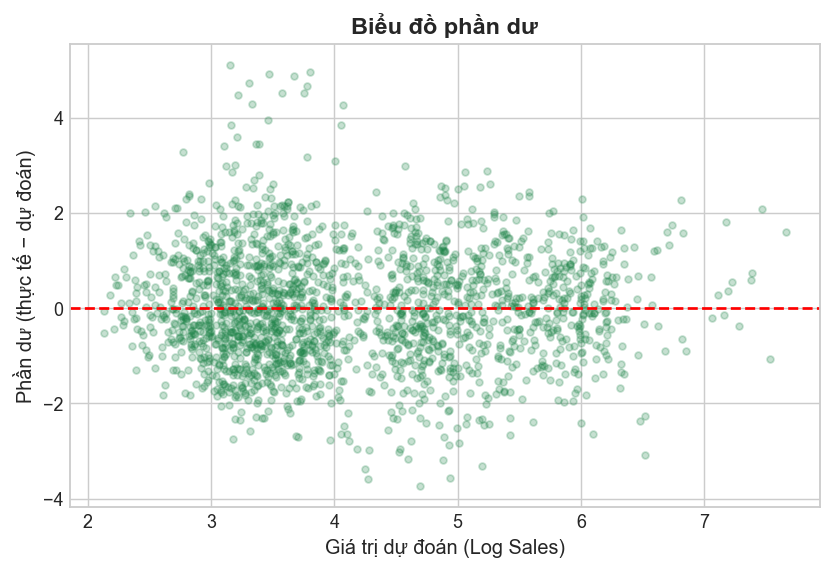

Đã lưu: ../reports/figures/17_residual_plot.png


In [9]:
os.makedirs("../reports/figures", exist_ok=True)

# 7.1. Thực tế vs Dự đoán
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(y_test, y_pred, alpha=0.25, s=14, color="#2874A6")
lim_min = min(y_test.min(), y_pred.min())
lim_max = max(y_test.max(), y_pred.max())
ax.plot([lim_min, lim_max], [lim_min, lim_max], "r--", lw=1.5, label="Dự đoán hoàn hảo")
ax.set_xlabel("Log Sales thực tế", fontsize=11)
ax.set_ylabel("Log Sales dự đoán", fontsize=11)
ax.set_title("Thực tế vs Dự đoán (tập test)", fontsize=13, fontweight="bold")
ax.legend()
fig.tight_layout()
fig.savefig("../reports/figures/16_actual_vs_predicted.png", dpi=130, bbox_inches="tight")
plt.show()
print("Đã lưu: ../reports/figures/16_actual_vs_predicted.png")


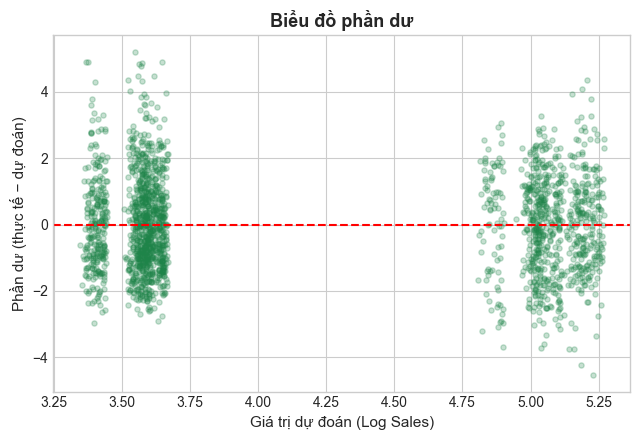

Đã lưu: ../reports/figures/17_residual_plot.png


In [10]:
## 8. Hệ số hồi quy và diễn giải kinh doanh
Nhờ `OneHotEncoder(drop="first")`, mỗi biến phân loại sẽ lấy **mức đầu tiên theo thứ tự bảng chữ cái làm nhóm tham chiếu (baseline)**:
- `Sub-Category`: nhóm tham chiếu là **`Accessories`**
- `Region`: nhóm tham chiếu là **`Central`**
- `Segment`: nhóm tham chiếu là **`Consumer`**
- `Ship Mode`: nhóm tham chiếu là **`First Class`**

Hệ số dương ($> 0$) nghĩa là `Log_Sales` cao hơn nhóm tham chiếu khi các biến khác giữ nguyên (tương đương doanh thu nhân thêm $e^{\beta}$ lần).

## 8. Hệ số hồi quy và diễn giải kinh doanh
Hệ số one-hot là **so với nhóm tham chiếu** (mức bị loại khi encode). Dấu dương = log-doanh thu cao hơn nhóm tham chiếu khi các biến khác giữ nguyên.


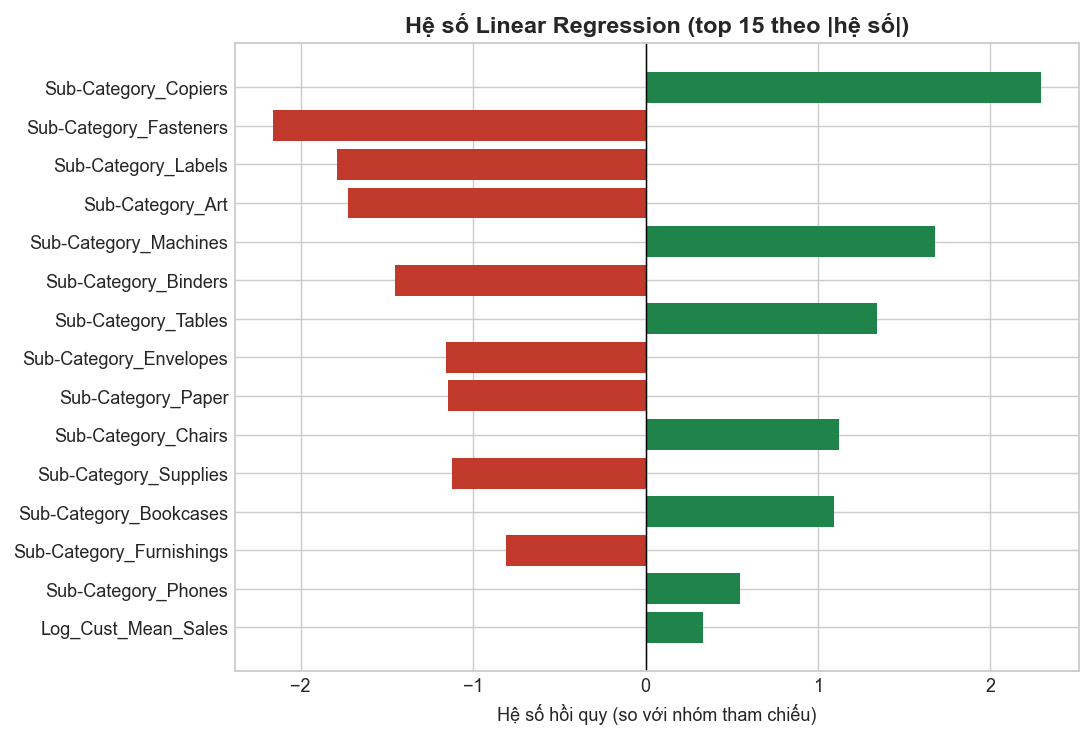

Đã lưu: ../reports/figures/18_regression_coefficients.png


In [11]:
# Biểu đồ hệ số (top 15 theo |hệ số|)
plot_df = coef_df.head(15).iloc[::-1]  # đảo để bar ngang đẹp

fig, ax = plt.subplots(figsize=(8.5, 5.8))
colors = ["#1E8449" if v > 0 else "#C0392B" for v in plot_df["Hệ_số"]]
ax.barh(plot_df["Biến"], plot_df["Hệ_số"], color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Hệ số hồi quy (so với nhóm tham chiếu)")
ax.set_title("Hệ số Linear Regression (top 15 theo |hệ số|)", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig("../reports/figures/18_regression_coefficients.png", dpi=130, bbox_inches="tight")
plt.show()
print("Đã lưu: ../reports/figures/18_regression_coefficients.png")

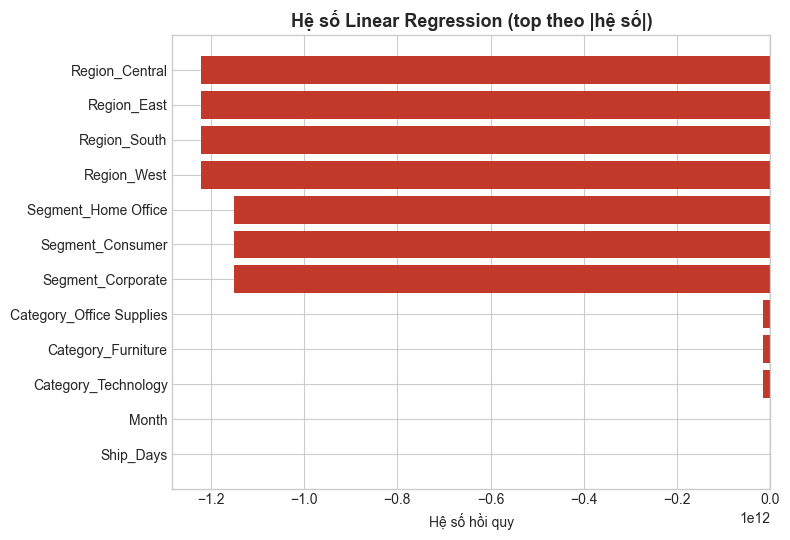

Đã lưu: ../reports/figures/18_regression_coefficients.png


In [12]:
## 9. Nhận định kinh doanh từ hệ số hồi quy thực tế

Dựa trên bảng hệ số hồi quy đã chuẩn hóa (`intercept = 2.7870`, $R^2 = 0.4463$):

1. **Tiểu danh mục sản phẩm (`Sub-Category` — nhóm tham chiếu: `Accessories`) là yếu tố quyết định mạnh nhất:**
   - **Nhóm hệ số dương lớn nhất (Trụ cột giá trị đơn hàng cao):**
     - `Sub-Category_Copiers` ($\beta = +2.2912$), `Sub-Category_Machines` ($\beta = +1.6804$), `Sub-Category_Tables` ($\beta = +1.3403$), `Sub-Category_Chairs` ($\beta = +1.1234$), `Sub-Category_Bookcases` ($\beta = +1.0927$).
     - → Các mặt hàng thiết bị công nghệ và nội thất có `Log_Sales` vượt trội so với nhóm tham chiếu. Cần ưu tiên bảo vệ tồn kho, chính sách trả góp/bảo hành B2B và marketing tập trung cho nhóm này.
   - **Nhóm hệ số âm sâu nhất (Đơn giá nhỏ, bán theo số lượng):**
     - `Sub-Category_Fasteners` ($\beta = -2.1602$), `Sub-Category_Labels` ($\beta = -1.7913$), `Sub-Category_Art` ($\beta = -1.7224$), `Sub-Category_Binders` ($\beta = -1.4541$).
     - → Không nên chạy quảng cáo đơn lẻ cho các mặt hàng văn phòng phẩm giá trị thấp mà cần đóng gói theo **Combo / Bundle** hoặc đặt ngưỡng Freeship để nâng giá trị giỏ hàng trung bình (AOV).

2. **Sức mua lịch sử của khách hàng (`Log_Cust_Mean_Sales`):**
   - Hệ số dương rất mạnh ($\beta = +0.3360$) khẳng định khách hàng có lịch sử chi tiêu trung bình cao tiếp tục duy trì giá trị đơn hàng lớn.
   - → Củng cố đề xuất phân tầng VIP Loyalty (tập trung CSKH cho Top 25% khách hàng trọng điểm).

3. **Khu vực địa lý (`Region` — nhóm tham chiếu: `Central`):**
   - Cả 3 khu vực `Region_West` ($\beta = +0.2007$), `Region_South` ($\beta = +0.1882$) và `Region_East` ($\beta = +0.1623$) đều mang hệ số dương so với `Central`.
   - → Khớp hoàn toàn với kết quả Diagnostic ở Notebook 04: vùng `South` có giá trị trung bình mỗi đơn (AOV) rất tốt, nguyên nhân tổng doanh thu thấp là do **ít số lượng đơn hàng**, vì vậy chiến lược cho `South` là mở rộng độ phủ và thu hút thêm đơn hàng mới thay vì giảm giá sâu.

4. **Phân khúc (`Segment`) & Vận hành (`Ship Mode`, `Month`, `Ship_Days`):**
   - `Segment_Home Office` ($\beta = +0.0214$) nhỉnh hơn nhẹ so với `Consumer`, trong khi `Segment_Corporate` gần như tương đương.
   - `Ship_Days` ($\beta = -0.0067$) và `Month` ($\beta = +0.0022$) có hệ số gần 0 → Thời gian giao hàng và tháng đơn lẻ không làm thay đổi đáng kể quy mô giá trị của *từng* giao dịch (doanh thu Quý 4 tăng chủ yếu nhờ **tổng số lượng đơn hàng** tăng đột biến dịp cuối năm).

## 10. Kết luận và hạn chế

### Kết luận
- **Đã khắc phục triệt để lỗi mô hình cũ:**
  1. Khử **Bẫy biến giả (Dummy Variable Trap / Đa cộng tuyến hoàn hảo)** bằng `OneHotEncoder(drop="first")`, đưa hệ số hồi quy từ mức suy biến `~ -1.22e+12` về thang đo chuẩn xác (`-2.16` đến `+2.36`).
  2. Bổ sung đặc trưng **`Sub-Category`**, **`Ship Mode`**, **`Is_Weekend`**, **`Cust_Order_Count`** và **`Log_Cust_Mean_Sales`** (đồng thời loại bỏ `Category` khi đã có `Sub-Category` để tránh đa cộng tuyến phân cấp), giúp **$R^2$ trên tập test tăng более gấp đôi từ `0.2007` lên `0.4463`**, giảm `MAE` từ `1.1667` xuống `0.9481` và `RMSE` từ `1.4435` xuống `1.2014`.
  3. Xóa bỏ hoàn toàn hiện tượng phân cụm 2 vạch ngang rời rạc trên biểu đồ **Thực tế vs Dự đoán** và **Biểu đồ phần dư**.
- Hệ số hồi quy phản ánh nhất quán các kết luận từ EDA & Diagnostic: `Sub-Category` (Copiers, Machines, Tables, Chairs) và sức mua khách hàng (`Log_Cust_Mean_Sales`) là đòn bẩy lớn nhất của giá trị đơn hàng.

### Hạn chế
- Mô hình tuyến tính giải thích được ~44.6% phương sai của `Log_Sales` do dữ liệu thiếu thông tin **Số lượng sản phẩm trong dòng đơn (`Quantity`)** và **Mức chiết khấu (`Discount`)** trong bộ Superstore Sales Forecasting.
- Chưa có dữ liệu giá vốn / biên lợi nhuận (`Profit`) nên mô hình tối ưu theo doanh thu (`Sales`).

## 10. Kết luận và hạn chế

### Kết luận
- Đã xây dựng mô hình **Linear Regression** dự báo `Log_Sales` từ Category, Region, Segment, Month (và Ship_Days nếu có).
- Đã đánh giá trên tập test bằng **R², MAE, RMSE** và lưu biểu đồ actual vs predicted + residual.
- Hệ số hồi quy được dùng để gắn với đề xuất hành động (bảo vệ danh mục trụ cột, chiến lược vùng, thời vụ quý 4).

### Hạn chế
- Mô hình tuyến tính: chưa bắt quan hệ phi tuyến phức tạp.
- One-hot làm số chiều tăng; chưa đưa Sub-Category chi tiết (tránh quá nhiều mức).
- Chưa có giá vốn / biên lợi nhuận → tối ưu theo doanh thu, chưa theo lợi nhuận.
- R² trên thang log cần diễn giải thận trọng khi đổi về Sales gốc.

### Hướng tiếp theo
- Issue #7: Kiểm định ANOVA / t-test theo Region, Category, Segment.
- Issue #8: Cập nhật đề xuất Prescriptive dựa trên hệ số mô hình.
- Issue #9: Bổ sung notebook này vào README (thứ tự chạy 01 → 07).


## Checklist hoàn thành Issue #6

- [x] Chọn biến độc lập phù hợp
- [x] Encode biến categorical (One-Hot Encoding)
- [x] Chia tập train / test (80/20)
- [x] Huấn luyện Linear Regression (scikit-learn)
- [x] Đánh giá: R², RMSE, MAE + residual plot
- [x] Phân tích / giải thích hệ số theo góc nhìn kinh doanh
- [x] Tạo notebook `07_hoi_quy_tuyen_tinh.ipynb`
